In [1]:
from pathlib import Path
import pandas as pd
import nibabel as nib
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score
import numpy as np
import pickle
import random
import SimpleITK as sitk
import cv2
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset
import numpy as np
from torchvision import transforms
import mysql.connector
import os
from PIL import ImageOps
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import vtk
from scipy.spatial.transform import Rotation as R
from scipy.interpolate import RegularGridInterpolator
import matplotlib.pyplot as plt


In [2]:
res_size = (96, 48, 128)

base_folder = Path(r"/home/varhai/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp")
skull_file = base_folder / "combined_skull_analysis.xlsx"

images_folder = r"/home/varhai/PRIMUS/var_vestlontest/export/images/"
conn = mysql.connector.connect(option_files=os.path.expanduser('~/.my.cnf')) 
sql_query = """
SELECT o.SPECIMEN_ID,s.STRAIN,s.GENDER, m.COHORT_ID, e.DATE,o.VALUE_CATEGORY as SkullShape, LEN.VALUE_DATA_POINT as CraniumLength,COM.VALUE_TEXT as Comment
FROM OBSERVATION as o
    INNER JOIN MOUSE as m ON o.SPECIMEN_ID = m.ID
    INNER JOIN SPECIMEN as s ON m.ID = s.ID
    INNER JOIN EXPERIMENT as e ON e.ID = o.EXPERIMENT_ID
    INNER JOIN PARAMETER as p ON o.PARAMETER_STABLE_ID = p.PARAMETER_STABLE_ID
    LEFT JOIN (
        SELECT SPECIMEN_ID, VALUE_TEXT
        FROM OBSERVATION
        WHERE PARAMETER_STABLE_ID = 'CCP_XRY_032_001'
    ) AS COM ON o.SPECIMEN_ID = COM.SPECIMEN_ID

    LEFT JOIN (
        SELECT SPECIMEN_ID, VALUE_DATA_POINT
        FROM OBSERVATION
        WHERE PARAMETER_STABLE_ID = 'CCP_XRY_893_001'
    ) AS LEN ON o.SPECIMEN_ID = LEN.SPECIMEN_ID
WHERE
    m.COHORT_ID LIKE 'c%'
    AND o.PARAMETER_STABLE_ID = 'CCP_XRY_001_001';
"""
# Reading data into a Pandas DataFrame
db_df_test = pd.read_sql(sql_query, conn)
skull_df = pd.read_excel(skull_file)

<ipython-input-2-71c5e1e08e1a>:31: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  db_df_test = pd.read_sql(sql_query, conn)


In [3]:
# match sutures with database
# Defining your SQL query


sql_query = """
SELECT SPECIMEN_ID, VALUE_IMAGE_URI FROM `OBSERVATION` WHERE `PARAMETER_STABLE_ID` = 'CCP_XRY_051_001' AND `INCREMENT_VALUE` = '001'
 and VALUE_IMAGE_URI is not null 
"""
# Reading data into a Pandas DataFrame
db_df = pd.read_sql(sql_query, conn)

# Closing the connection
conn.close()
display(db_df)

<ipython-input-3-d2dfdf71a5cf>:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  db_df = pd.read_sql(sql_query, conn)


,SPECIMEN_ID,VALUE_IMAGE_URI
0,064-EPJ77,2018-07-11/nub1_f_83z-epj77_cr1.bmp
1,064-EPJ81,2018-07-11/nub1_m_064-epj81_cr1.bmp
2,064-EPJ82,2018-07-11/nub1_m_064-epj82_cr1.bmp
3,064-EPJ85,2018-07-11/nub1_f_83z-epj85_cr1.bmp
4,064-EPJ86,2018-07-11/nub1_f_83z-epj86_cr1.bmp
...,...,...
10337,E83-F2740,2020-08-24/fam161b_m_e83-f2740_cr1.bmp
10338,E83-F2743,2020-08-24/fam161b_f_e83-f2743_cr1.bmp
10339,E83-F2749,2021-01-22/fam161b_f_e83-f2749_cr1.bmp
10340,E83-F2750,2021-01-22/fam161b_f_e83-f2750_cr1.bmp


# Filter subjects with skull data which have sutures

In [35]:
# merge the dataframes
skull_df["Specimen_ID"] = skull_df["Unnamed: 0"].apply(lambda x: x.split("_")[-1])
skull_df = skull_df.merge(db_df, left_on="Specimen_ID", right_on="SPECIMEN_ID")

skull_df["sutures_status"] = skull_df['Comment'].apply(lambda x: ("sutures"in str(x).lower() and "open" in str(x).lower()
                                                                 # and "severe" in str(x).lower()
                                                                 ))
skull_df = skull_df[skull_df['proc_dist']<3000]


In [36]:
# get 2 classes for sutures (equal number of sutures and no sutures)
sutures_df = skull_df[skull_df['sutures_status']==True]
no_sutures_df = skull_df[skull_df['sutures_status']==False]
#no_sutures_df = no_sutures_df.sample(n=sutures_df.shape[0], random_state=42)

In [37]:
# generate train and test split take equal number of sutures and no sutures for each
no_sutures_df = no_sutures_df.sample(frac=1, random_state=42)
no_sutures_df = no_sutures_df.iloc[:sutures_df.shape[0]]
train_df = pd.concat([sutures_df.iloc[:int(sutures_df.shape[0]*0.8)], no_sutures_df.iloc[:int(sutures_df.shape[0]*0.8)]])
test_df = pd.concat([sutures_df.iloc[int(sutures_df.shape[0]*0.8):], no_sutures_df.iloc[int(sutures_df.shape[0]*0.8):]])
# randomize the dataset
train_df = train_df.sample(frac=1, random_state=42)
test_df = test_df.sample(frac=1, random_state=42)

In [4]:
import numpy as np
import nibabel as nib
import vtk
from scipy.spatial.transform import Rotation as R
import cv2
from tqdm import tqdm
import os
from PIL import ImageOps
import torch
import torchvision.transforms as transforms






def get_head_file_n_mesh(subj_id, cohort_id):
    """
    Get the head file and mesh file for a given subject and cohort
    :param subj_id: 
    :param cohort_id: 
    :return: 
    """
    folders = [x for x in base_folder.iterdir() if cohort_id in x.name and (x/"skull_shape_workdir").exists()]
    for fold in folders:
        files = list((fold/"skull_shape_workdir").iterdir())
        for file in files:
            if str(subj_id) in file.name:
                if (file/"head_affine_registered.obj").exists() and (file/"coregistered_head.nii.gz").exists():
                    return file/"head_affine_registered.obj", file/"coregistered_head.nii.gz"
    return None, None


def get_points_from_mesh(mesh_file):
    pt1_id = [9567, 9449]
    pt2_id = [7752, 24168]
    pt3_id = [17278, 16945]

    reader = vtk.vtkOBJReader()
    reader.SetFileName(str(mesh_file))
    reader.Update()
    polydata = reader.GetOutput()

    points = polydata.GetPoints()
    pts1 = [points.GetPoint(pt1_id[0]), points.GetPoint(pt1_id[1])]
    pts2 = [points.GetPoint(pt2_id[0]), points.GetPoint(pt2_id[1])]
    pts3 = [points.GetPoint(pt3_id[0]), points.GetPoint(pt3_id[1])]
    return np.mean(pts1, axis=0), np.mean(pts2, axis=0), np.mean(pts3, axis=0)


def world_to_voxel(world_coords, affine):
    """Convert world coordinates to voxel coordinates."""
    inv_affine = np.linalg.inv(affine)
    voxel_coords = nib.affines.apply_affine(inv_affine, world_coords)
    return voxel_coords


def plane_projection(head_data, points_world, head_affine):
    v1 = points_world[1] - points_world[0]
    v2 = points_world[2] - points_world[0]
    normal = np.cross(v1, v2)
    normal_vector = normal / np.linalg.norm(normal)

    # Calculate the plane constant
    d = -np.dot(normal, points_world[0])
    
    # Generate a grid of points on the plane
    num_points = 800  # Higher resolution for the slice
    grid_u, grid_v = np.meshgrid(np.linspace(-1, 2, num_points), np.linspace(-1, 1, num_points))
    grid_points = points_world[0] + np.outer(grid_u.ravel(), v1) + np.outer(grid_v.ravel(), v2)

    # Interpolate the image data at these points
    dims = head_data.shape
    x = np.arange(dims[0])
    y = np.arange(dims[1])
    z = np.arange(dims[2])
    interpolator = RegularGridInterpolator((x, y, z), head_data, method='linear', bounds_error=False, fill_value=0)
    
    # Convert the grid points back to voxel coordinates
    grid_points_voxel = nib.affines.apply_affine(np.linalg.inv(head_affine), grid_points)
    
    # Ensure grid points are within the volume bounds
    grid_points_voxel = np.clip(grid_points_voxel, 0, np.array(dims) - 1)
    
    # Interpolate the values at the grid points
    slice_data = interpolator(grid_points_voxel).reshape(num_points, num_points)
    
    # compute d as 10mm / 100
    d = 10 / 100
    # produce 100 parallel planes to the original one to generate a projection image
    slices = []
    for i in range(100):
        slice_data = get_parallel_plane(head_data, grid_points, head_affine, normal_vector, d*(i+1), num_points)
        slices.append(slice_data)
    
    # produce the projection image as the maximum value of the 100 parallel planes
    slice_data = np.max(slices, axis=0)
    
    # Visualize the slice
    plt.imshow(slice_data, cmap='gray')
    plt.title('Slice Defined by a Plane')
    plt.axis('off')
    plt.show()

    return slice_data        

def get_parallel_plane(head_data, grid_points, 
                       head_affine, normal_vector, d, num_points=400):
    # Interpolate the image data points shifted by the normal vector and d
    dims = head_data.shape
    x = np.arange(dims[0])
    y = np.arange(dims[1])
    z = np.arange(dims[2])
    interpolator = RegularGridInterpolator((x, y, z), head_data, method='linear', bounds_error=False, fill_value=0)
    
    # shift the grid points by the normal vector and d
    grid_points_shifted = grid_points + d * normal_vector
    
    # Convert the grid points back to voxel coordinates
    grid_points_voxel = nib.affines.apply_affine(np.linalg.inv(head_affine), grid_points_shifted)
    
    return interpolator(grid_points_voxel).reshape(num_points, num_points)

def read_plane(subj_id, cohort_id):
    mesh_file, head_file = get_head_file_n_mesh(subj_id, cohort_id)
    if mesh_file is None:
        return None
    head_img = nib.load(head_file)
    head_data = head_img.get_fdata()
    # filter fdata
    head_data[head_data<34] = 0 
    head_data[head_data >70] = 70 
    head_affine = head_img.affine
    points_world = get_points_from_mesh(mesh_file)
    plane = plane_projection(head_data, points_world, head_affine)
    return plane


def read_subjs(df, process=lambda x: x, is_process=False, folder=None):
    results = []
    for i in tqdm(range(df.shape[0])):
        subj = dict(df.iloc[i])
        clas_res = subj['sutures_status']
        
        image = read_plane(subj['Specimen_ID'], subj['COHORT_ID'])
        if image is None:
            continue
        
        res = {"class": clas_res, "image": image}
        results.append(res)
        if is_process:
            cv2.imwrite(os.path.join(folder, f'{i}_{clas_res}.png'), image)
    return results


# Read training and test data
train_data = read_subjs(train_df, is_process=True, folder=r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/train_set_proj')
test_data = read_subjs(test_df, is_process=True, folder=r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/test_set_proj')


NameError: name 'train_df' is not defined

In [5]:
# reload the data after manual removal of heads

def read_from_files(folder):
    results = []
    # Iterate over each file in the directory
    for filename in tqdm(os.listdir(folder)):
        # Construct the full image path
        image_path = os.path.join(folder, filename)
        
        # Extract class information from the filename
        clas_res = True if "True" in filename else False
        
        # Read the image in grayscale
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        
        # Create the result dictionary
        res = {"class": clas_res, "image": image}
        
        # Append the result to the results list
        results.append(res)
    
    return results



train_data = read_from_files(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/train_set_sutures')
test_data = read_from_files(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/test_set_sutures')



100%|██████████| 235/235 [00:09<00:00, 25.16it/s]


In [53]:
# count how many sutures and no sutures per train and test data

print("Train", sum([1 for x in train_data if x['class'] == True]))
print("Test", sum([1 for x in test_data if x['class'] == True]))


Train 497
Test 125


In [6]:
class MouseSuturesDataset(Dataset):
    def __init__(self, data, augment=False):
        self.data = data
        self.augment = augment

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx]['image']
        min_im = image.min()
        max_im = image.max()
        image = (image - min_im) / (max_im - min_im)
        image = torch.tensor(image, dtype=torch.float32)

        image = image.unsqueeze(0)  # Add channel dimension
        if self.augment and random.random() > 0.5:
            image = self._augment_image(image)

        label = self.data[idx]['class']
        label = self._convert_class_to_int(label)
        return image, label

    def _convert_class_to_int(self, class_value):
        return torch.tensor(int(class_value), dtype=torch.long)

    def _augment_image(self, image):
        # Randomly choose which augmentation to apply
        if random.random() > 0.2:
            image = self._random_shift(image)
        if random.random() > 0.2:
            image = self._add_gaussian_noise(image)
        return image

    def _random_shift(self, image, max_shift=5):
        # Randomly shift the image along each axis
        shift_h, shift_w = np.random.randint(-max_shift, max_shift+1, size=2)
        image = torch.roll(image, shifts=(shift_h, shift_w), dims=(1, 2))
        return image

    def _add_gaussian_noise(self, image, mean=0, std=0.1):
        noise = torch.randn(image.size()) * std + mean
        image = image + noise
        image = torch.clamp(image, 0, 1)  # Ensure values are within [0, 1]
        return image

In [ ]:

save_folder = r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/test_data_sutures'#,process_image

In [ ]:
test_df.to_csv("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/test_data_sutures/test_names.csv")

In [ ]:
sutures_df.describe()

In [ ]:
import torchvision

In [ ]:
torchvision.models.googlenet()

In [7]:

vgg = models.vgg16(weights=models.VGG16_Weights.DEFAULT).to(device)

vgg.classifier[6] = nn.Linear(4096, 1).to(device)
train_dataset = MouseSuturesDataset(train_data, True)
test_dataset = MouseSuturesDataset(test_data, False)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=1, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=False)

# 
# # Replace the final layer with a custom one
# num_ftrs = resnet50.fc.in_features
# resnet50.fc = nn.Linear(num_ftrs, 1).to(device)  # Assuming you're doing a regression task

In [ ]:
from matplotlib.pyplot import imsave

class InvertGrayscalePIL:
    def __call__(self, image):
        return ImageOps.invert(image)

transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Lambda(InvertGrayscalePIL()), 
    #transforms.Lambda(lambda x: x.crop((60, 100, x.width-60, x.height-120))),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor()
])




num_epochs = 500


best_val_loss = 1000


criterion = nn.L1Loss()
#vgg = resnet50
optimizer = torch.optim.Adam(vgg.classifier.parameters(), lr=1e-5)

early_stopping_patience = 15

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=10, factor=0.5)
epoch_losses = []
val_losses = []
for epoch in range(500):
    vgg.train()
    running_loss = 0.0
    for inputs, labels in tqdm(train_loader):
        
        inputs, labels = transform(inputs.squeeze(0).float()).to(device), labels.float().to(device)
        
        optimizer.zero_grad()
        outputs = vgg(inputs.unsqueeze(0))
        outputs = torch.sigmoid(outputs)
        #print(outputs)
        #print(outputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    epoch_loss = running_loss / len(train_loader.dataset)
    vgg.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = transform(inputs.squeeze(0).float()).to(device), labels.float().to(device)
            outputs = vgg(inputs.unsqueeze(0))
            outputs = torch.sigmoid(outputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() #* inputs.size(0)
    
    val_loss = val_loss / len(test_loader.dataset)
    val_losses.append(val_loss)
    scheduler.step(val_loss)
    
    print(f'Epoch {epoch+1}/{num_epochs}, Training Loss: {epoch_loss:.4f}, Validation Loss: {val_loss:.4f}')
    epoch_losses.append(epoch_loss)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(vgg.state_dict(), 'best_model_sutures_gen.pth')
    else:
        patience_counter += 1
        if patience_counter >= early_stopping_patience:
            print("Early stopping triggered")
            break  

  0%|          | 0/926 [00:00<?, ?it/s]/usr/local/lib/python3.8/dist-packages/torch/nn/modules/loss.py:101: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([1, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.l1_loss(input, target, reduction=self.reduction)
100%|██████████| 926/926 [03:59<00:00,  3.86it/s]


Epoch 1/500, Training Loss: 0.4444, Validation Loss: 0.3841


100%|██████████| 926/926 [03:59<00:00,  3.87it/s]


Epoch 2/500, Training Loss: 0.3812, Validation Loss: 0.3236


100%|██████████| 926/926 [03:58<00:00,  3.88it/s]


...

100%|██████████| 926/926 [03:58<00:00,  3.88it/s]


Epoch 39/500, Training Loss: 0.2476, Validation Loss: 0.2912


100%|██████████| 926/926 [03:58<00:00,  3.89it/s]

Epoch 41/500, Training Loss: 0.2517, Validation Loss: 0.2778


100%|██████████| 926/926 [03:58<00:00,  3.89it/s]


In [ ]:
true_positives = 0
true_negatives = 0
false_positives = 0
false_negatives = 0
torch.cuda.empty_cache()
vgg.eval()
#vgg.to('cpu')
# load the best model
vgg.load_state_dict(torch.load('best_model_sutures_gen.pth'))
torch.cuda.empty_cache()
#vgg = vgg.to('cpu')
result_computed = []
folder_save = r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/false_detections_sutures'
i=0
with torch.no_grad():
    for inputs, labels in tqdm(test_loader):
        orig_inp = inputs
        #inputs, labels = transform(inputs.squeeze(0).float()).to('cpu'), labels.float().to('cpu')
        inputs, labels = transform(inputs.squeeze(0).float()).to(device), labels.float().to(device)
    
        outputs = vgg(inputs.unsqueeze(0))
        outputs = torch.sigmoid(outputs)
        #print(outputs)
        # save outputs and label to a list
        result_computed.append((outputs, labels))
        predicted_class = outputs > 0.5 # threshold at 0.5
        true_class = labels
        if true_class == 1 and predicted_class == 1:
            true_positives += 1
        elif true_class == 0 and predicted_class == 0:
            true_negatives += 1
        elif true_class == 0 and predicted_class == 1:
            false_positives += 1
            # save fp image to a folder
            print(orig_inp.shape)
            imsave(os.path.join(folder_save, f'fp_{i}.png'), inputs.squeeze(0)
                   .cpu().numpy()) 
        elif true_class == 1 and predicted_class == 0:
            false_negatives += 1
            #imsave(os.path.join(folder_save, f'fn_{i}.png'), inputs.squeeze(0).cpu().numpy()) 
        torch.cuda.empty_cache()
        i+=1

accuracy = (true_positives + true_negatives) / (true_positives + true_negatives + false_positives + false_negatives)
precision = true_positives / (true_positives + false_positives)
recall = true_positives / (true_positives + false_negatives)
f1_score = 2 * precision * recall / (precision + recall)
print(f'Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {f1_score:.4f}')
        #print(outputs.argmax(0))

In [ ]:
print(true_positives, true_negatives, false_positives , false_negatives)

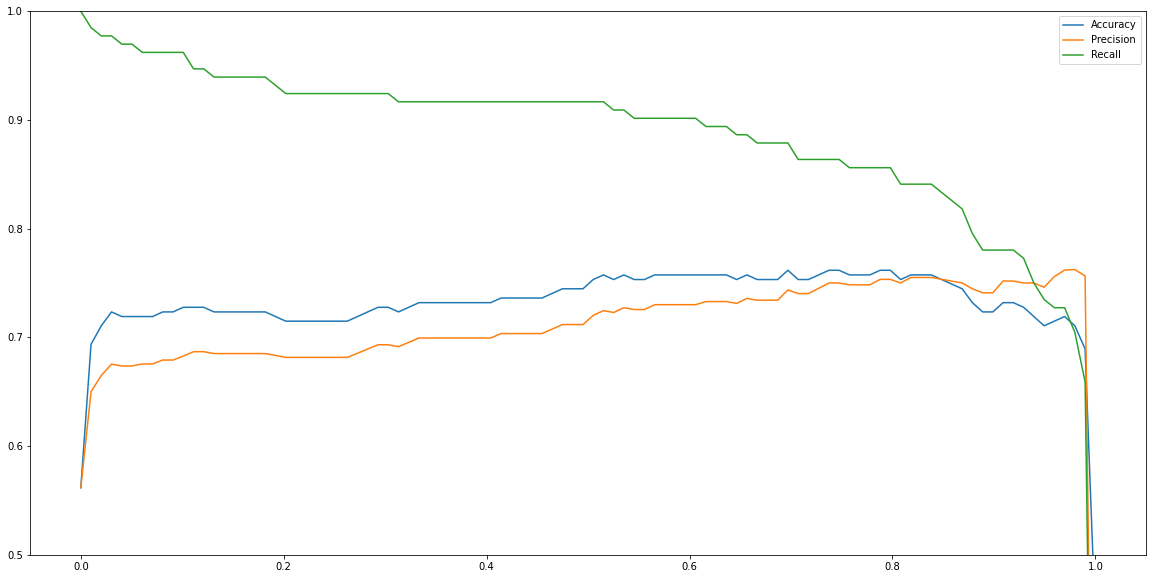

In [24]:
# plot accuracy precision and recall according to different thresholds
thresholds = np.linspace(0, 1, 100)
accuracies = []
precisions = []
recalls = []
f1_scores = []

for threshold in thresholds:
    true_positives = 0
    true_negatives = 0
    false_positives = 0
    false_negatives = 0
    for outputs, labels in result_computed:
        predicted_class = outputs > threshold
        true_class = labels
        if true_class == 1 and predicted_class == 1:
            true_positives += 1
        elif true_class == 0 and predicted_class == 0:
            true_negatives += 1
        elif true_class == 0 and predicted_class == 1:
            false_positives += 1
        elif true_class == 1 and predicted_class == 0:
            false_negatives += 1
    accuracy = (true_positives + true_negatives) / (true_positives + true_negatives + false_positives + false_negatives)
    if true_positives > 0:
        precision = true_positives / (true_positives + false_positives)
    else:
        precision = 0
    if true_positives > 0:
        recall = true_positives / (true_positives + false_negatives)
    else:
        recall = 0
    #f1_score = 2 * precision * recall / (precision + recall)
    accuracies.append(accuracy)
    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1_score)
    
import matplotlib.pyplot as plt
plt.figure(figsize=(20,10))
plt.plot(thresholds, accuracies, label='Accuracy')
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.ylim([0.5,1])
plt.legend()
# set figure size



In [ ]:
os.path.exists(r"/home/varhai/PRIMUS/var_vestlontest/export/images")

In [ ]:
from torchvision.transforms import Invert


In [ ]:
train_df

In [ ]:
classifier_is_top.to("cpu")

In [ ]:
no_sutures_df

In [11]:
class InvertGrayscalePIL:
    def __call__(self, image):
        return ImageOps.invert(image)

transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Lambda(InvertGrayscalePIL()), 
    transforms.Lambda(lambda x: x.crop((60, 100, x.width-60, x.height-120))),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor()
])
